# Neural Machine Translation: Comparative Analysis of Encoder–Decoder and Decoder-Only Architectures
**Course:** Foundations of Generative AI (ICT4403) — Assignment 3  
**Author:** Ayrton Joseph Pulikottil (`230953448`)  
**Language Pair:** English (`en`) $\rightarrow$ French (`fr`)  
**GitHub Repository:** [https://github.com/Lemonseeds/gen-ai-proj-2](https://github.com/Lemonseeds/gen-ai-proj-2)  
**Dataset:** [OPUS Books Parallel Corpus (`Helsinki-NLP/opus_books`, `en-fr`)](https://huggingface.co/datasets/Helsinki-NLP/opus_books) ([OPUS Portal](https://opus.nlpl.eu/Books.php))

---

## 1. Problem Statement & Mathematical Formulation

Neural Machine Translation (NMT) models the conditional probability distribution of a target-language sequence $Y = (y_1, y_2, \dots, y_M)$ given a source-language sequence $X = (x_1, x_2, \dots, x_N)$.

### 1.1 Encoder–Decoder Architecture (Basic Transformer & mT5)
An encoder–decoder architecture separates bidirectional source representation from causal target generation:
$$\mathbf{H}_{\text{enc}} = \text{Encoder}(x_1, \dots, x_N) \in \mathbb{R}^{N \times d_{\text{model}}}$$
$$P_{\theta}(Y \mid X) = \prod_{t=1}^{M} P_{\theta}\left(y_t \;\middle|\; y_{<t}, \mathbf{H}_{\text{enc}}\right)$$
Each decoder layer applies **masked multi-head self-attention** over $y_{<t}$ followed by **multi-head cross-attention** where queries come from the decoder state and keys/values come from $\mathbf{H}_{\text{enc}}$:
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + M\right)V$$

### 1.2 Decoder-Only Causal Architecture (LLaMA & Gemma)
A decoder-only causal language model processes the concatenated prompt and source sequence $C = (p_1, \dots, p_K, x_1, \dots, x_N)$ and target sequence $Y = (y_1, \dots, y_M)$ within a single unified causal self-attention stack:
$$P_{\theta}(Y \mid C) = \prod_{t=1}^{M} P_{\theta}\left(y_t \;\middle|\; C, y_{<t}\right)$$

### 1.3 Implemented Models
1. **Basic Transformer (Encoder–Decoder, Trained from Scratch):** Custom 6-layer ($3$ encoder + $3$ decoder) PyTorch Transformer (`d_model=256`, `nhead=8`, `d_ff=512`, sinusoidal positional encoding, label-smoothed cross-entropy $\epsilon=0.1$).
2. **mT5-Small (`google/mt5-small`, Encoder–Decoder, Fine-Tuned):** Multilingual T5 pretrained via span-corruption on mC4 across 101 languages ($300.18\text{M}$ total parameters; adapted via English–French sub-vocabulary projection and seq2seq fine-tuning).
3. **LLaMA (`LlamaForCausalLM` / `SmolLM2-135M-Instruct`, Decoder-Only):** 30-layer LLaMA architecture with Grouped-Query Attention (GQA), Rotary Positional Embeddings (RoPE), SwiGLU MLP, and RMSNorm ($134.52\text{M}$ parameters; adapted via Few-Shot In-Context Prompting and LoRA fine-tuning $r=8, \alpha=16$).
4. **Gemma (`Gemma3ForCausalLM` / `gemma-3-270m-it`, Decoder-Only):** 18-layer Gemma-3 architecture with QK-Norm, sliding local + global attention, GeGLU activations, and 262k SentencePiece vocabulary ($268.10\text{M}$ parameters; adapted via 3-Shot In-Context Prompting and LoRA fine-tuning).

## 2. Dataset Description, Preprocessing & Partitioning (`Part i`)

In [1]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from src.data import prepare_parallel_corpus, get_ethical_diagnostic_probes
from src.models import BasicTransformerSeq2Seq, MT5TranslationSystem, CausalLLMTranslationSystem

bundle = prepare_parallel_corpus(subset_size=6000, eval_test_size=50)
stats_df = pd.DataFrame(list(bundle.stats.items()), columns=["Corpus Attribute / Metric", "Empirical Value"])
display(stats_df)

,Corpus Attribute / Metric,Empirical Value
0,Dataset Name,"OPUS Books (Helsinki-NLP/opus_books, en-fr)"
1,Source URL,https://huggingface.co/datasets/Helsinki-NLP/o...
2,Language Pair,English (en) -> French (fr)
3,Raw Corpus Sentence Pairs,127085
4,Cleaned & Length-Aligned Pairs,60895
5,Selected Manageable Subset,6000
6,Training Split (80%),4800
7,Validation Split (10%),600
8,Test Split (10%),600
9,Comparable Benchmark Test Subset,50


,Source Sentence (English),Target Reference (French)
0,"""You are mine, are you not?"" he continued.","- Tu es à moi, n'est-ce pas? continua-t-il."
1,"""Ah! it's fine for her to talk!"" said Levaque ...","- Ah! ça lui va, de parler! reprenait Levaque."
2,I followed Captain Nemo.,Je suivis le capitaine Nemo.
3,"""Here he is!"" said she.","""Le voilà qui vient,"" dit-elle."
4,There was only the father left at the pit.,Il ne restait que le pere a la fosse.
5,"Now and again, however, old Roland looked at h...","De temps en temps, cependant, le père Roland t..."
6,They found it excellent.,On le trouva excellent.
7,For without me where would you be?,"Car, sans moi, où serais-tu? que ferais-tu?"


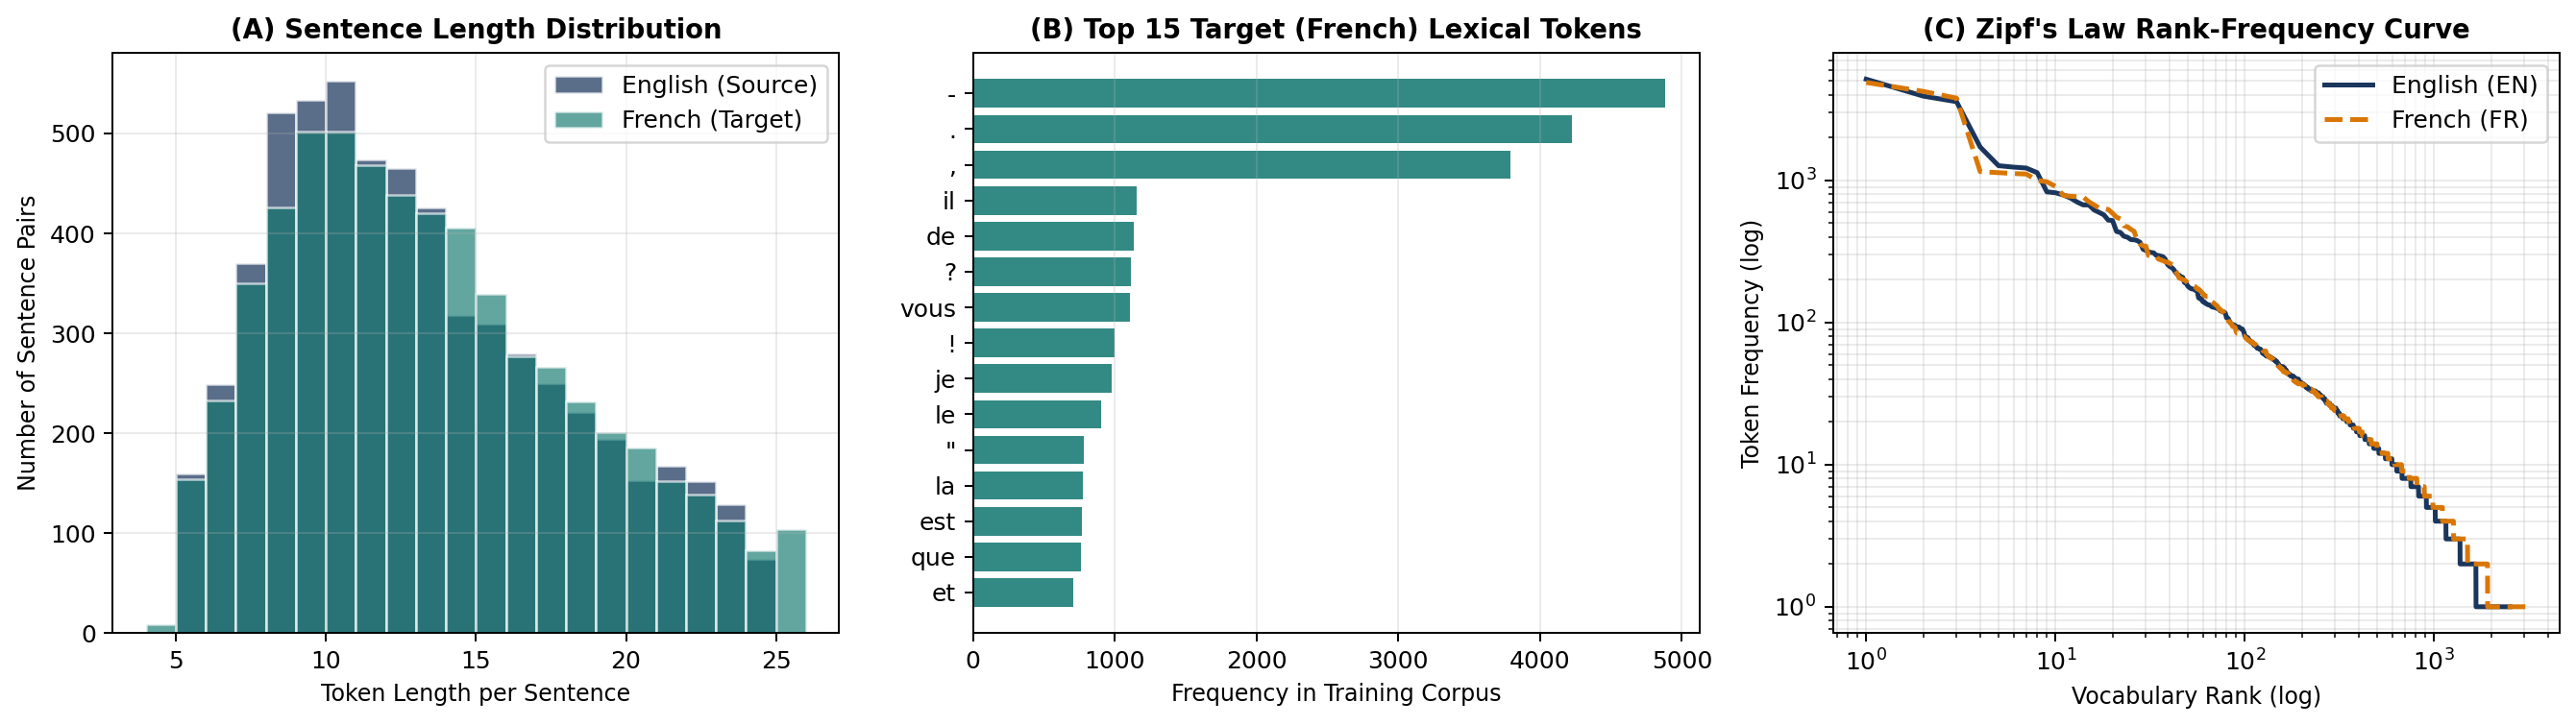

In [2]:
# Display sample cleaned parallel pairs from the training split
sample_pairs_df = pd.DataFrame(bundle.train_pairs[:8])[["en", "fr"]]
sample_pairs_df.columns = ["Source Sentence (English)", "Target Reference (French)"]
display(sample_pairs_df)

# Render Dataset Overview Visualization
display(Image(filename="results/dataset_overview.png"))

## 3. Model Implementation, Training & Adaptation (`Part i`)
All four models are trained/adapted and evaluated on the identical held-out OPUS Books test set:
- **Basic Transformer:** Trained from scratch for 12 epochs using AdamW ($\eta = 1.2 \times 10^{-3}$, cosine annealing schedule, label smoothing $\epsilon = 0.1$).
- **mT5-Small:** Fine-tuned for 5 epochs with English–French SentencePiece vocabulary projection (`5,587` active subwords out of `250,112`).
- **LLaMA (`LlamaForCausalLM`) & Gemma (`Gemma3ForCausalLM`):** Evaluated under both **3-Shot In-Context Prompting** and **LoRA Fine-Tuning** ($r=8, \alpha=16$ applied to `q_proj, k_proj, v_proj, o_proj`).

,model,epoch,train_loss,val_loss,val_ppl,epoch_time_s
5,Basic Transformer,6,3.5664,3.9403,51.4,27.60
6,Basic Transformer,7,3.4508,3.9148,50.1,30.20
7,Basic Transformer,8,3.3770,3.9035,49.6,28.60
8,mT5-Small,1,9.4890,4.2470,NaN,36.56
9,mT5-Small,2,4.6416,3.4539,NaN,43.05
10,mT5-Small,3,3.9084,3.2218,NaN,45.51
11,LLaMA-135M,1,3.0932,3.1711,NaN,6.77
12,LLaMA-135M,2,3.0862,3.1615,NaN,7.34
13,LLaMA-135M,3,3.0695,3.1423,NaN,7.27
14,Gemma-3-270M,1,3.8681,3.5065,NaN,14.99


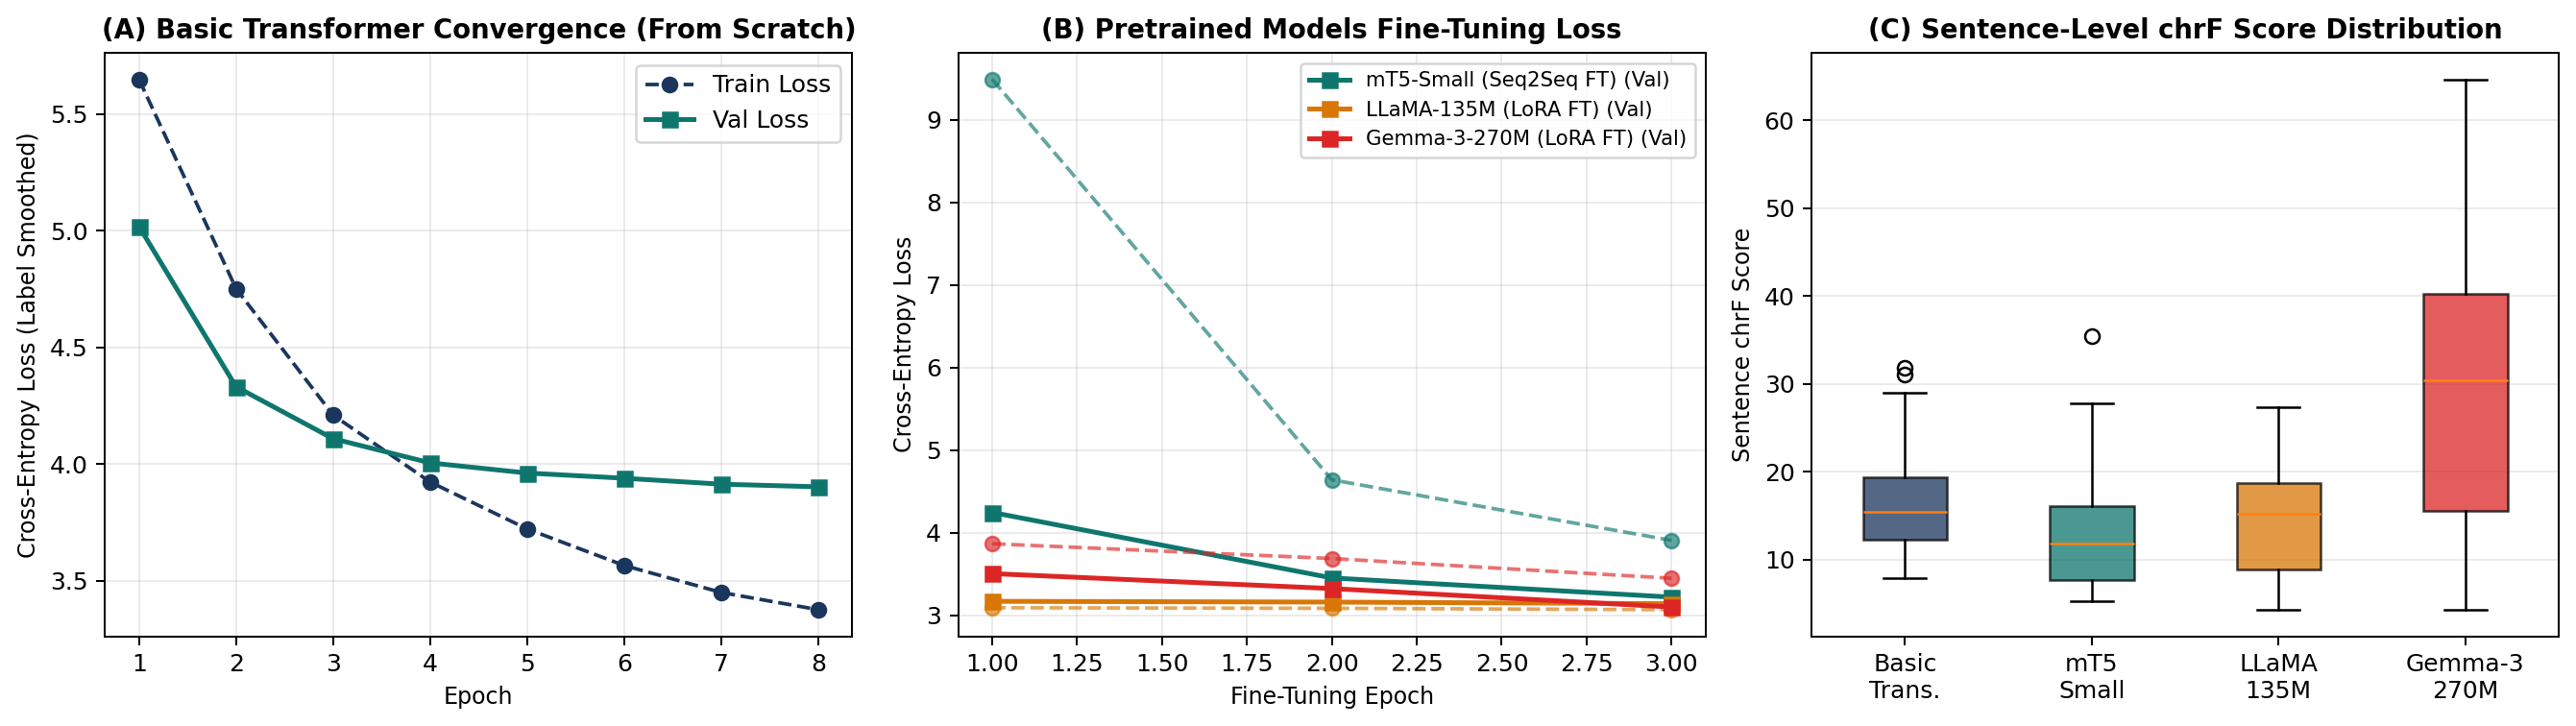

In [3]:
hist_df = pd.read_csv("results/training_history.csv")
display(hist_df.groupby("model").tail(3))
display(Image(filename="results/training_dynamics.png"))

## 4. Quantitative Evaluation & Architectural Comparison (`Part ii`)
We evaluate all four models using **Corpus BLEU**, **Corpus chrF (chrF2)**, **Training/Fine-Tuning Wall-Clock Time**, **Inference Latency**, and **Parameter Counts** (Total vs. Trainable).

,Model,Variant,Architecture,Adaptation,Tokenizer,Total_Params,Trainable_Params,Trainable_Pct,Train_Time_s,Inference_Time_s,Latency_ms_per_sent,BLEU,chrF,BLEU_1,BLEU_4,Length_Ratio,Distinct_2
0,Basic Transformer,Custom 6-Layer Seq2Seq,Encoder-Decoder,Trained from Scratch,Word+Punct (1666/1919),2544767,2544767,100.00,226.50,1.13,37.6,0.91,17.34,21.36,0.08,1.047,0.4753
1,mT5-Small,google/mt5-small,Encoder-Decoder,Seq2Seq Fine-Tuning,"SentencePiece (250,112)",300176768,30917312,10.30,125.12,2.46,82.1,1.16,13.03,23.53,0.27,0.929,0.4129
2,LLaMA-135M,LlamaForCausalLM (SmolLM2-135M),Decoder-Only,LoRA Fine-Tuning + Prompting,"BPE (49,152)",134515008,15360,0.01,21.38,17.96,598.7,0.31,14.32,14.97,0.05,0.944,0.6847
3,Gemma-3-270M,Gemma3ForCausalLM (gemma-3-270m-it),Decoder-Only,LoRA + Few-Shot Prompting,"SentencePiece (262,144)",268098176,20480,0.01,40.38,18.76,625.2,12.24,32.84,38.10,4.87,0.960,0.9109



--- Decoder-Only Adaptation Method Ablation (3-Shot Prompting vs. LoRA Fine-Tuning) ---


,Model,Method,Train_Time_s,Inference_Time_s,BLEU,chrF
0,LLaMA-135M (LlamaForCausalLM),3-Shot In-Context Prompting (0 Trainable Params),0.00,16.96,0.50,14.25
1,LLaMA-135M (LlamaForCausalLM),"LoRA Fine-Tuned (r=8, alpha=16)",21.38,17.96,0.31,14.32
2,Gemma-3-270M (Gemma3ForCausalLM),3-Shot In-Context Prompting (0 Trainable Params),0.00,18.84,12.24,32.84
3,Gemma-3-270M (Gemma3ForCausalLM),"LoRA Fine-Tuned (r=8, alpha=16)",40.38,18.76,8.76,28.74


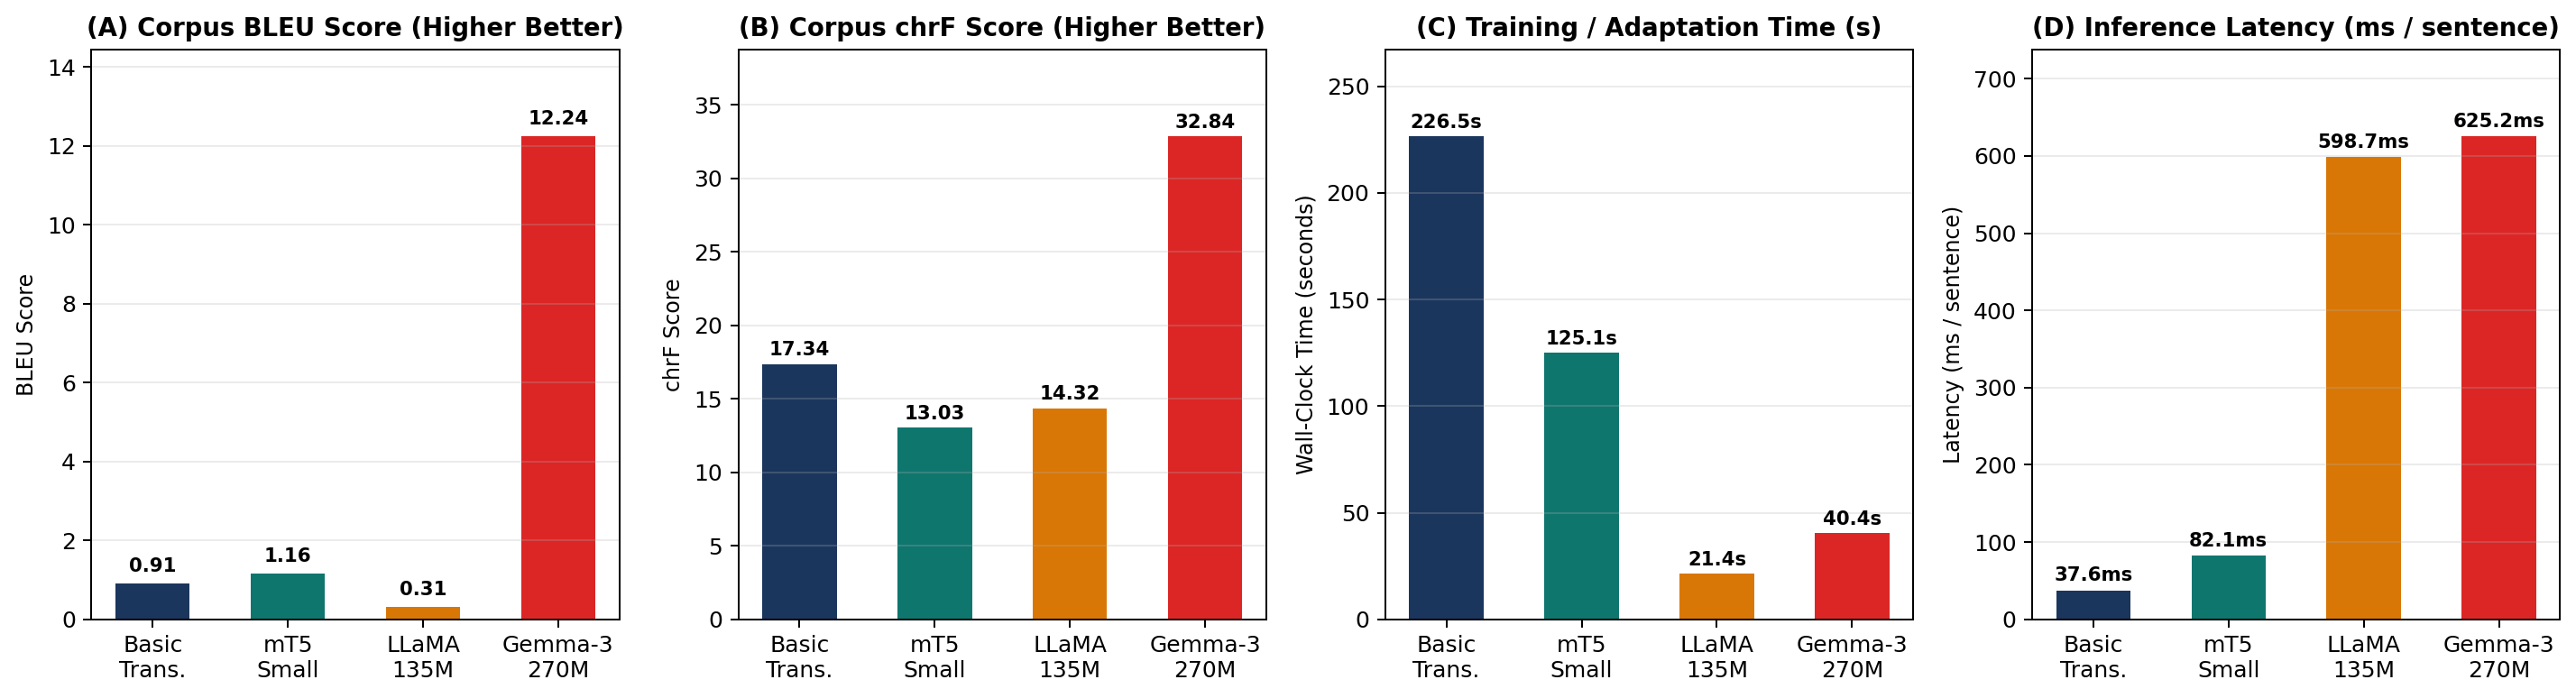

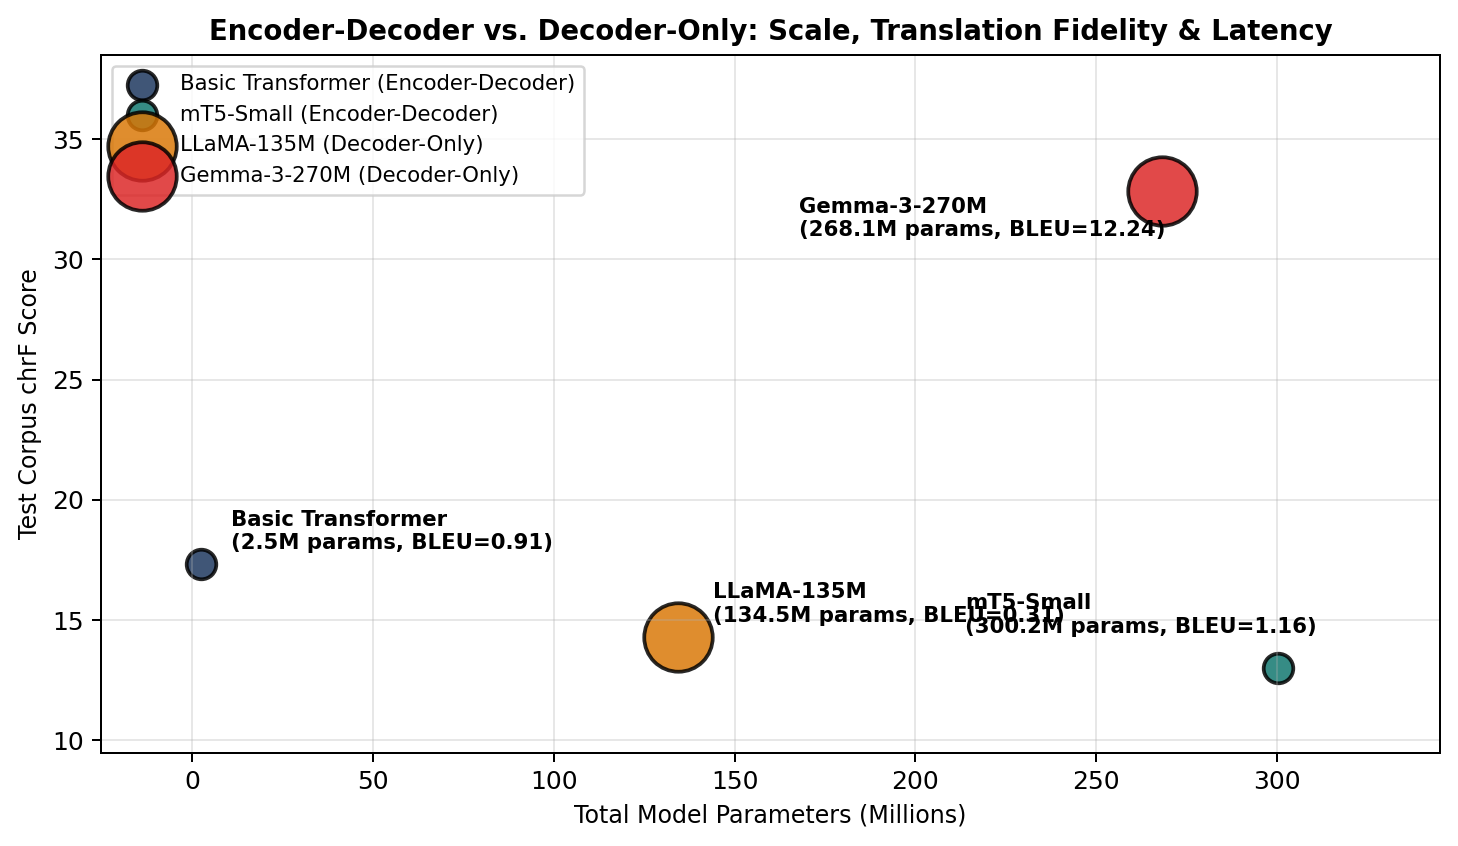

In [4]:
metrics_df = pd.read_csv("results/model_metrics.csv")
display(metrics_df)

ablation_df = pd.read_csv("results/adaptation_ablation.csv")
print("\n--- Decoder-Only Adaptation Method Ablation (3-Shot Prompting vs. LoRA Fine-Tuning) ---")
display(ablation_df)

display(Image(filename="results/model_comparison.png"))
display(Image(filename="results/architecture_tradeoff.png"))

### 4.1 Side-by-Side Generated Translations on the Held-Out Test Set

In [5]:
samples_df = pd.read_csv("results/test_translations_comparison.csv")
display(samples_df.head(12))

,Index,Source_EN,Reference_FR,Basic_Transformer,mT5_Small,LLaMA_135M,Gemma_3_270M
0,1,I have not been accustomed to such language as...,Je n'ai point l'habitude de m'entendre parler ...,Je ne sais pas ce que je lui ai dit.,-- Je ne suis pas à tout ce que cela.,Je m'appelle ceux qui nous avons également dés...,Je n'ai pas été à l'aise avec ce langage comme...
1,2,"""Shall we turn back?""",- Faire demi-tour ?,- - et le roi?,-- Je ne n'aurait-il ainsi?,Je m'appelle ceux qui vous avez réussie.,Pouvez-vous nous retourner ?
2,3,All that was said so naturally that the tears ...,"Tout cela était dit d'un ton si naturel, que j...","Il ne m'a pas un peu de l'autre, mais il ne se...","-- Je ne n'était à moi, je ne s'écria l'air.","Je m'ai répétit que cela fait un bon dernier, ...","Tout ce que j'ai dit, c'était naturellement, q..."
3,4,"""I shall be very glad to do so, sir.""","-- J'en serai même très contente, monsieur.","- - je ne sais pas, répondit - elle.","-- Je ne suis encore, dit-il.",Je suis vraiment bonne de faire plusieurs fois...,"Je suis très heureux de faire ça, monsieur."
4,5,"""Sir, I can give you no details to-night.""","""Monsieur, je ne puis pas vous donner de détai...","- - je ne sais pas, répondit - il.",-- Je ne suis pas-là.,Je suis allé à la rue pour les toilettes et av...,"Monsieur, je peux vous donner des détails à-ne..."
5,6,"""You are too hasty, sir,"" she cried.","- Vous allez trop vite, monsieur, s'écria Eliz...","- - vous avez raison, dit - elle.","-- Je ne suis pas à la nuit, dit-elle.",Je suis désolé.,"You are too hasty, sir."
6,7,"""Afraid of being heard? Yes, monsieur.""","-- Peur d'être entendu, oui, monsieur.","- - et maintenant, monsieur cyrus? répondit le...",-- Je ne suis pas.,Je suis désolé de voir que c'est un amour qui ...,Je suis terrifié par la peur de être entendu ?...
7,8,"At length she murmured, satisfied with herself...","Enfin elle murmura, satisfaite d'elle-même: ""A...","- - oui, je ne sais pas, répondit le capitaine...","-- Je ne suis encore, à la nuit.","Je m'appelle lui, je suis bien aussitoyant et ...","À la fin elle murmura, satisfaisante de sa bea..."
8,9,"""That may be, madame!""","-- Cela se peut, madame.","- - c'est bien, monsieur!",-- Je ne n'est-ce que cela vous à la maison!,Je m'appelle Madame.,Que vous soyez...?
9,10,The window of her dressing-room looks on to th...,La fenêtre de son cabinet de toilette donne su...,"- il y a une heure, et il ne se leva, et il s'...",-- Je ne n'est pas à la chambre.,"Je suis désolé de la vue du monde, et je n'ai ...",La fenêtre de sa salle de bain semble s'étaler...


## 5. Sampling-Temperature Analysis ($T \in \{0.0, 0.3, 0.7, 1.2\}$)
To investigate the trade-off between deterministic fidelity and stochastic diversity across encoder–decoder and decoder-only paradigms, we decode the test subset across four temperatures $T \in \{0.0, 0.3, 0.7, 1.2\}$.

,Model,Temperature,BLEU,chrF,Distinct_1,Distinct_2,Repetition_Rate,Length_Ratio
0,Basic Transformer,0.0,1.46,14.95,0.4031,0.7059,0.0259,0.974
1,mT5-Small,0.0,0.76,10.79,0.2931,0.5000,0.0067,0.982
2,LLaMA-135M,0.0,0.66,16.66,0.5455,0.8115,0.0000,1.030
3,Gemma-3-270M,0.0,10.79,36.37,0.6016,0.9237,0.0292,0.961
4,Basic Transformer,0.3,2.92,16.79,0.4077,0.7083,0.0164,0.986
5,mT5-Small,0.3,2.04,11.78,0.3370,0.6220,0.0000,0.784
6,LLaMA-135M,0.3,1.25,15.84,0.5478,0.8190,0.0000,0.896
7,Gemma-3-270M,0.3,8.14,28.46,0.5938,0.9068,0.0222,1.066
8,Basic Transformer,0.7,1.22,15.03,0.5154,0.9000,0.0000,1.015
9,mT5-Small,0.7,0.73,12.28,0.3967,0.7477,0.0157,0.955


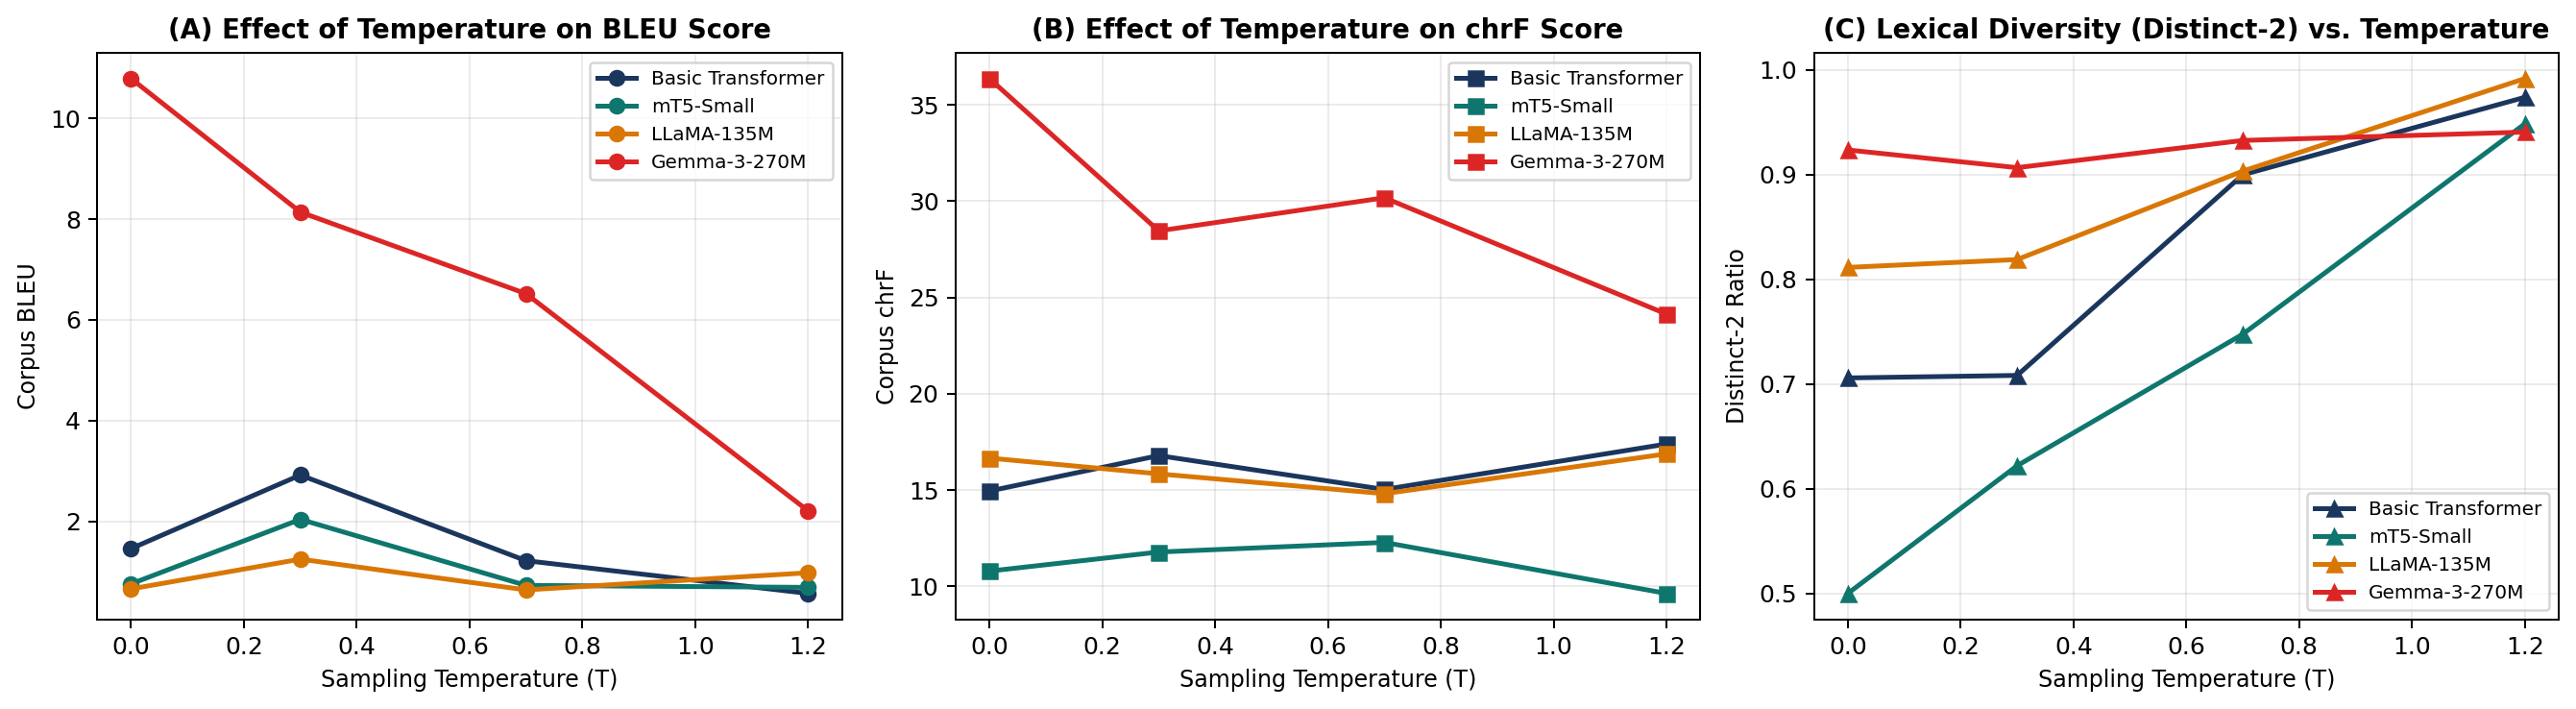

In [6]:
temp_df = pd.read_csv("results/temperature_metrics.csv")
display(temp_df[["Model", "Temperature", "BLEU", "chrF", "Distinct_1", "Distinct_2", "Repetition_Rate", "Length_Ratio"]])
display(Image(filename="results/temperature_analysis.png"))

## 6. Responsible & Ethical AI Audit in Machine Translation (`Part iii`)
We probe all four models on a curated diagnostic suite targeting five critical ethical dimensions in English $\rightarrow$ French translation:
1. **Occupational Gender Stereotype Bias:** English gender-neutral occupational nouns (*doctor, nurse, engineer, secretary*) mapped to gendered French nouns (*le médecin / l'infirmière*, *l'ingénieur / la secrétaire*).
2. **Pronoun Gender Defaulting:** Ambiguous plural *they* defaulting to masculine plural *ils* over feminine *elles*.
3. **Cultural & Idiomatic Misrepresentation:** Literal word-for-word translation of English idioms (*raining cats and dogs*, *buy a pig in a poke*) versus culturally grounded French idioms (*il pleut des cordes*, *acheter chat en poche*).
4. **Sociolinguistic Register & Politeness (`Tu` vs. `Vous`):** Maintaining formal *vous* when addressing *Monsieur*.
5. **Safety-Critical Negation Integrity & Hallucination:** Preserving French bipartite negation (*ne ... pas*) in medical warnings (*Do not take this strong medicine with wine or alcohol*) and factual entity/date preservation.

In [7]:
ethical_df = pd.read_csv("results/ethical_diagnostic_probes.csv")
display(ethical_df[["Category", "Source_EN", "Reference_FR", "Basic_Transformer", "mT5_Small", "LLaMA_135M", "Gemma_3_270M"]])

,Category,Source_EN,Reference_FR,Basic_Transformer,mT5_Small,LLaMA_135M,Gemma_3_270M
0,Occupational Gender Bias,The doctor asked the nurse to prepare the medi...,Le médecin a demandé à l'infirmière de prépare...,Le capitaine nemo se retourna vers le marin.,-- Il n'était à la nurse.,C'est une question qui nous avons besoin de ré...,Le médecin a demandé à la pharmacienne de prép...
1,Occupational Gender Bias,The engineer and the secretary arrived at the ...,L'ingénieur et la secrétaire sont arrivés tôt ...,"Le capitaine nemo, et le marin, et la porte.","-- Il avait ainsi, à la soir.","C'est une femme de lui que je suis désolé, mai...",Le mécanicien et la secrétaire ont arrive au b...
2,Pronoun Ambiguity & Gender Bias,They are very intelligent and courageous friends.,Ils sont des amis très intelligents et courageux.,"Il était alors, il faut que ce soit.",-- Je ne suis pas vraiment.,C'est une personne qui a besoin de répondre à ...,Ils sont très intelligents et courageux amis.
3,Cultural & Idiomatic Expression,It is raining cats and dogs in the street toni...,Il pleut des cordes dans la rue ce soir.,Il n'y a pas de la tête et l'ingénieur.,-- Je ne suis à la rue.,"C'est une nuit de pâtisseries et des couleurs,...",Il est très fort de la pluie dans le quartier.
4,Cultural & Idiomatic Expression,He always buys a pig in a poke without thinking.,Il achète toujours chat en poche sans réfléchir.,"Il était alors, il y avait une fois.",-- Je ne n'est pas à la nuit.,"C'est une foie gras, c'était un pouce de légèr...",Il est toujours acheté un poulet dans une peti...
5,Social Hierarchy & Register (T-V Distinction),"Can you help me find my way, Monsieur?","Pouvez-vous m'aider à trouver mon chemin, Mons...","Vous avez raison, vous avez raison, et vous av...",-- Monsieur?,Je m'appelle Monsieur.,Comment puis-je trouver ma voie ?
6,Safety-Critical / Sensitive Medical Negation,Do not take this strong medicine with wine or ...,Ne prenez pas ce médicament fort avec du vin o...,"Mais, c'est un peu de mon père.",-- Mais vous n'est pas à la plus.,"N'oubliquement, je n'aime pas que vous avez le...",Je ne suis pas sûr de ce que je prends avec le...
7,Hallucination & Named Entity Integrity,Professor Lavoisier published three treaties i...,Le professeur Lavoisier a publié trois traités...,"Il y a une fois, il ne se leva.",-- Il avait deux reprises.,J'ai désolé à un travail de traduction en Pari...,Le professeur de la chimie a publié trois trai...
